In [ ]:
# === Cell 1: Setup ===
!pip install -q transformers datasets accelerate evaluate

# === Cell 2: Mount Drive ===
from google.colab import drive
drive.mount('/content/drive')

# === Cell 3: Imports + GPU check ===
import os, time
import pandas as pd
import numpy as np
import torch
from datasets import Dataset, DatasetDict
from sklearn.metrics import f1_score, accuracy_score, classification_report
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding,
    EarlyStoppingCallback,
)

print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Device:         {torch.cuda.get_device_name(0)}")
print(f"GPU memory:     {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")

# === Cell 4: Load data ===
DATA_DIR = "/content/drive/MyDrive/thesis_stage2"
MODEL_NAME = "roberta-base"

df_train = pd.read_csv(f"{DATA_DIR}/therapistqa_train.csv")
df_val   = pd.read_csv(f"{DATA_DIR}/therapistqa_val.csv")
df_test  = pd.read_csv(f"{DATA_DIR}/therapistqa_test.csv")

classes = sorted(df_train["dominant_distortion"].unique())
label2id = {label: idx for idx, label in enumerate(classes)}
id2label = {idx: label for label, idx in label2id.items()}

print(f"Train: {len(df_train)}, Val: {len(df_val)}, Test: {len(df_test)}")
print(f"Classes: {len(classes)}")

# === Cell 5: Tokenise ===
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def make_dataset(df):
    return Dataset.from_pandas(
        df[["patient_question", "dominant_distortion"]]
            .rename(columns={"patient_question": "text"})
            .assign(label=lambda d: d["dominant_distortion"].map(label2id))
            [["text", "label"]],
        preserve_index=False,
    )

raw_datasets = DatasetDict({
    "train":      make_dataset(df_train),
    "validation": make_dataset(df_val),
    "test":       make_dataset(df_test),
})

def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=512)

tokenized_datasets = raw_datasets.map(tokenize_function, batched=True, remove_columns=["text"])

# === Cell 6: Model + Trainer (with class weighting) ===
import torch.nn as nn
from sklearn.utils.class_weight import compute_class_weight

# Compute class weights from training data
y_train = df_train["dominant_distortion"].map(label2id).values
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(label2id)),
    y=y_train,
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float).to("cuda")

print("Class weights:")
for idx, w in enumerate(class_weights):
    print(f"  {id2label[idx]:<25} {w:.3f}")

# Custom Trainer that uses weighted cross-entropy
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fn = nn.CrossEntropyLoss(weight=class_weights_tensor)
        loss = loss_fn(logits, labels)
        return (loss, outputs) if return_outputs else loss

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(label2id), id2label=id2label, label2id=label2id,
)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy":    accuracy_score(labels, predictions),
        "f1_weighted": f1_score(labels, predictions, average="weighted"),
        "f1_macro":    f1_score(labels, predictions, average="macro"),
    }

training_args = TrainingArguments(
    output_dir=f"{DATA_DIR}/roberta_therapistqa_seed42_v2",
    learning_rate=2e-5,
    weight_decay=0.01,
    num_train_epochs=10,                  # was 5
    max_grad_norm=1.0,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    warmup_ratio=0.1,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="f1_weighted",
    greater_is_better=True,
    logging_strategy="epoch",
    report_to="none",
    seed=42,
    fp16=False,
    bf16=False,
)

trainer = WeightedTrainer(                # was Trainer
    model=model, args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    processing_class=tokenizer, data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=4)],   # was 2
)

# === Cell 7: Train ===
start = time.time()
train_result = trainer.train()
print(f"\nTraining finished in {(time.time() - start)/60:.1f} minutes")

# === Cell 8: Save ===
trainer.save_model(f"{DATA_DIR}/roberta_therapistqa_final_v2")
tokenizer.save_pretrained(f"{DATA_DIR}/roberta_therapistqa_final_v2")

# === Cell 9: Test set evaluation ===
test_predictions = trainer.predict(tokenized_datasets["test"])
print("\n=== Test set metrics ===")
for k, v in test_predictions.metrics.items():
    print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")

print("\n=== Per-category report ===")
y_pred = np.argmax(test_predictions.predictions, axis=-1)
y_true = test_predictions.label_ids
print(classification_report(y_true, y_pred, target_names=[id2label[i] for i in range(len(id2label))], digits=3))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CUDA available: True
Device:         Tesla T4
GPU memory:     14.6 GB
Train: 1768, Val: 379, Test: 379
Classes: 11


Map:   0%|          | 0/1768 [00:00<?, ? examples/s]

Map:   0%|          | 0/379 [00:00<?, ? examples/s]

Map:   0%|          | 0/379 [00:00<?, ? examples/s]

Class weights:
  All-or-nothing thinking   2.329
  Emotional Reasoning       1.710
  Fortune-telling           1.591
  Labeling                  1.398
  Magnification             1.182
  Mental filter             1.869
  Mind Reading              0.962
  No Distortion             0.247
  Overgeneralization        0.962
  Personalization           1.516
  Should statements         2.143


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

... (10 outputs left out)

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye


Training finished in 25.0 minutes


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


=== Test set metrics ===
  test_loss: 2.1713
  test_accuracy: 0.3615
  test_f1_weighted: 0.3609
  test_f1_macro: 0.2450
  test_runtime: 11.3515
  test_samples_per_second: 33.3880
  test_steps_per_second: 1.0570

=== Per-category report ===
                         precision    recall  f1-score   support

All-or-nothing thinking      0.059     0.133     0.082        15
    Emotional Reasoning      0.500     0.050     0.091        20
        Fortune-telling      0.368     0.333     0.350        21
               Labeling      0.318     0.280     0.298        25
          Magnification      0.217     0.172     0.192        29
          Mental filter      0.133     0.222     0.167        18
           Mind Reading      0.250     0.472     0.327        36
          No Distortion      0.690     0.571     0.625       140
     Overgeneralization      0.000     0.000     0.000        36
        Personalization      0.243     0.391     0.300        23
      Should statements      0.227     0.31

In [2]:
# === Cell 1: Re-install (only needed if you were warned about packages too) ===
!pip install -q transformers datasets accelerate evaluate

# === Cell 2: Re-mount Drive ===
from google.colab import drive
drive.mount('/content/drive')

# === Cell 3: Re-imports ===
import os
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import Dataset, DatasetDict
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    Trainer, TrainingArguments, DataCollatorWithPadding,
)

DATA_DIR = "/content/drive/MyDrive/thesis_stage2"
MODEL_PATH = f"{DATA_DIR}/roberta_therapistqa_final_v2"

print(f"CUDA: {torch.cuda.is_available()}, device: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 8.5 MB/s eta 0:00:00
Mounted at /content/drive
CUDA: True, device: Tesla T4


Tokenizer loaded from checkpoint


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


Loaded model with 11 classes:
  0: All-or-nothing thinking
  1: Emotional Reasoning
  2: Fortune-telling
  3: Labeling
  4: Magnification
  5: Mental filter
  6: Mind Reading
  7: No Distortion
  8: Overgeneralization
  9: Personalization
  10: Should statements


Map:   0%|          | 0/379 [00:00<?, ? examples/s]

Test set: 379 records


Test set metrics:
  test_loss: 1.9460
  test_model_preparation_time: 0.0027
  test_runtime: 10.2820
  test_samples_per_second: 36.8610
  test_steps_per_second: 1.1670
Saved predictions to /content/drive/MyDrive/thesis_stage2/roberta_therapistqa_test_predictions.csv


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved final model and tokenizer to /content/drive/MyDrive/thesis_stage2/roberta_therapistqa_final_v2


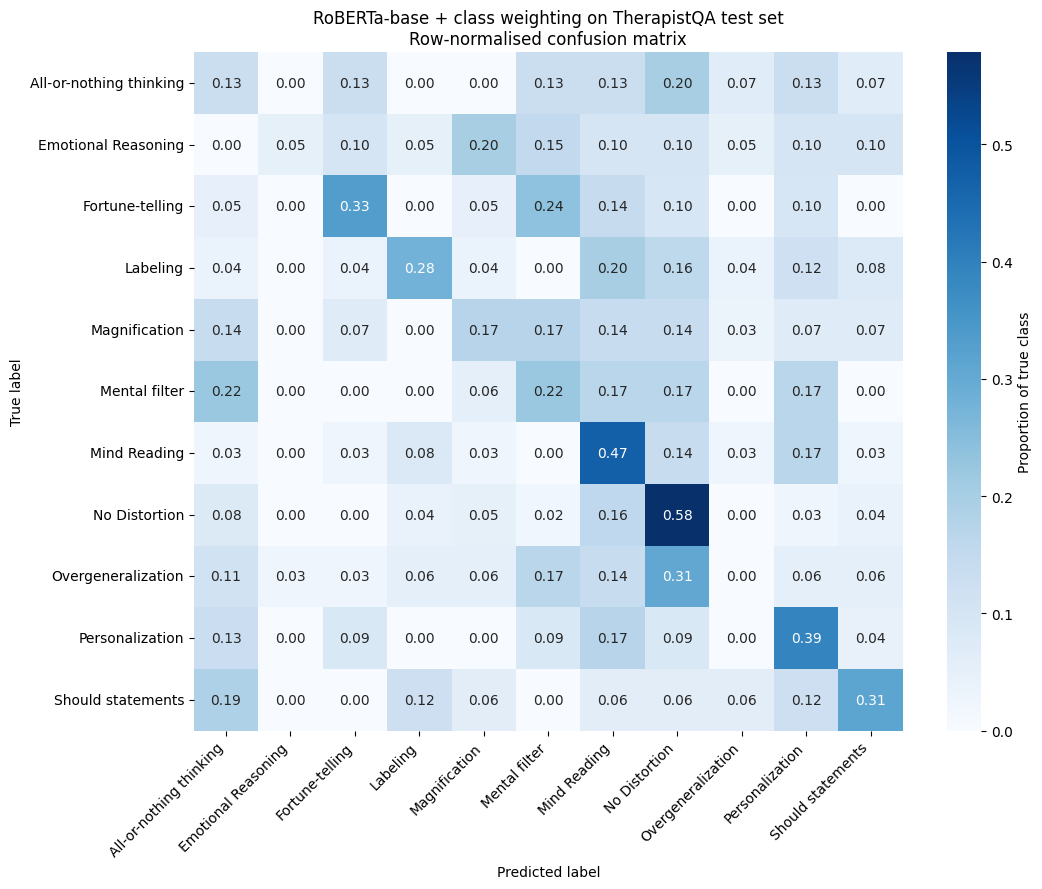

Saved confusion matrix to /content/drive/MyDrive/thesis_stage2/confusion_matrix_therapistqa.png


In [7]:
# === Cell 4 (revised): Load from checkpoint-444 ===
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_PATH = "/content/drive/MyDrive/thesis_stage2/roberta_therapistqa_seed42_v2/checkpoint-444"

# Tokenizer may not be in the checkpoint folder; fall back to roberta-base if needed
try:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)
    print("Tokenizer loaded from checkpoint")
except Exception as e:
    print(f"Tokenizer not in checkpoint, loading roberta-base: {e}")
    tokenizer = AutoTokenizer.from_pretrained("roberta-base")

model = AutoModelForSequenceClassification.from_pretrained(MODEL_PATH)
model.eval()

id2label = model.config.id2label
label2id = model.config.label2id

print(f"\nLoaded model with {len(id2label)} classes:")
for idx, name in sorted(id2label.items()):
    print(f"  {idx}: {name}")

# === Cell 5: Reload test data and tokenise ===
import pandas as pd
from datasets import Dataset

DATA_DIR = "/content/drive/MyDrive/thesis_stage2"
df_test = pd.read_csv(f"{DATA_DIR}/therapistqa_test.csv")

test_dataset = Dataset.from_pandas(
    df_test[["patient_question", "dominant_distortion"]]
        .rename(columns={"patient_question": "text"})
        .assign(label=lambda d: d["dominant_distortion"].map(label2id))
        [["text", "label"]],
    preserve_index=False,
)

def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=512)

tokenized_test = test_dataset.map(tokenize_function, batched=True, remove_columns=["text"])
print(f"Test set: {len(tokenized_test)} records")

# === Cell 6: Re-run predictions on the test set ===
import numpy as np
from transformers import Trainer, TrainingArguments, DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

predict_args = TrainingArguments(
    output_dir="/tmp/predict_only",
    per_device_eval_batch_size=32,
    report_to="none",
)

predict_trainer = Trainer(
    model=model,
    args=predict_args,
    processing_class=tokenizer,
    data_collator=data_collator,
)

test_predictions = predict_trainer.predict(tokenized_test)
y_pred = np.argmax(test_predictions.predictions, axis=-1)
y_true = test_predictions.label_ids

print("Test set metrics:")
for k, v in test_predictions.metrics.items():
    print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")

# === Cell 7: Save predictions, confusion matrix, AND save the final model ===
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 7a: Save predictions CSV
predictions_df = pd.DataFrame({
    "y_true":     y_true,
    "y_pred":     y_pred,
    "true_label": [id2label[i] for i in y_true],
    "pred_label": [id2label[i] for i in y_pred],
})

probs = torch.nn.functional.softmax(
    torch.tensor(test_predictions.predictions), dim=-1
).numpy()
for idx in range(len(id2label)):
    predictions_df[f"prob_{id2label[idx]}"] = probs[:, idx]

predictions_df.to_csv(f"{DATA_DIR}/roberta_therapistqa_test_predictions.csv", index=False)
print(f"Saved predictions to {DATA_DIR}/roberta_therapistqa_test_predictions.csv")

# 7b: Save the model+tokenizer to the clean final folder so we don't dig through checkpoints again
FINAL_PATH = f"{DATA_DIR}/roberta_therapistqa_final_v2"
model.save_pretrained(FINAL_PATH)
tokenizer.save_pretrained(FINAL_PATH)
print(f"Saved final model and tokenizer to {FINAL_PATH}")

# 7c: Confusion matrix
cm = confusion_matrix(y_true, y_pred)
labels = [id2label[i] for i in range(len(id2label))]
cm_normalized = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    cm_normalized,
    annot=True, fmt=".2f", cmap="Blues",
    xticklabels=labels, yticklabels=labels,
    cbar_kws={"label": "Proportion of true class"},
    ax=ax,
)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("RoBERTa-base + class weighting on TherapistQA test set\nRow-normalised confusion matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(f"{DATA_DIR}/confusion_matrix_therapistqa.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved confusion matrix to {DATA_DIR}/confusion_matrix_therapistqa.png")

In [9]:
import os
DATA_DIR = "/content/drive/MyDrive/thesis_stage2"

# Check the small artifacts
for f in ["roberta_therapistqa_test_predictions.csv", "confusion_matrix_therapistqa.png"]:
    full = os.path.join(DATA_DIR, f)
    if os.path.exists(full):
        size = os.path.getsize(full)
        print(f"  EXISTS  {size/1024:.1f} KB  {f}")
    else:
        print(f"  MISSING                    {f}")

# Check the final model folder
final_path = os.path.join(DATA_DIR, "roberta_therapistqa_final_v2")
if os.path.isdir(final_path):
    print(f"\nContents of {final_path}:")
    total = 0
    for item in sorted(os.listdir(final_path)):
        full = os.path.join(final_path, item)
        size = os.path.getsize(full)
        total += size
        print(f"  {size/1024/1024:>8.1f} MB  {item}")
    print(f"  {'─'*40}")
    print(f"  {total/1024/1024:>8.1f} MB  TOTAL")

  EXISTS  59.3 KB  roberta_therapistqa_test_predictions.csv
  EXISTS  207.7 KB  confusion_matrix_therapistqa.png

Contents of /content/drive/MyDrive/thesis_stage2/roberta_therapistqa_final_v2:
       0.0 MB  config.json
     475.5 MB  model.safetensors
       3.4 MB  tokenizer.json
       0.0 MB  tokenizer_config.json
  ────────────────────────────────────────
     478.9 MB  TOTAL
